# Baselines globales de corrección del pronóstico

Antes de entrenar modelos de corrección más complejos, hace falta un piso de referencia: ¿cuánto se puede mejorar el
pronóstico (`fcst_temp_c`) con reglas simples sobre la serie del error (`error_temp_c = fcst_temp_c - obs_temp_c`), sin
ningún modelo entrenado? Se prueban 4 baselines clásicos de series de tiempo -naive, naive estacional, media móvil,
drift- y se comparan contra no corregir nada (`error_predicho = 0`, confiar en el pronóstico tal cual).

Se trabaja sobre `temp_c`; la misma lógica aplica a las otras 3 variables cambiando `VARIABLE_OBJETIVO`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils import AZUL, NARANJA, GRIS_TEXTO, aplicar_estilo

PROCESSED = '../data/processed/'
OUT = '../data/out/modelado/'

aplicar_estilo()
figuras = {}  # se exportan todas al final

## 1. Carga y variable objetivo

In [2]:
VARIABLE_OBJETIVO = 'temp_c'

dataset = pd.read_csv(PROCESSED + 'dataset_modelado.csv')
dataset['target_hour_utc'] = pd.to_datetime(dataset['target_hour_utc'], utc=True)
dataset = dataset.sort_values(['station_id', 'target_hour_utc']).reset_index(drop=True)

COL_ERROR = f'error_{VARIABLE_OBJETIVO}'
COL_ABS_ERROR = f'abs_error_{VARIABLE_OBJETIVO}'
COL_FCST = f'fcst_{VARIABLE_OBJETIVO}'
COL_OBS = f'obs_{VARIABLE_OBJETIVO}'
COL_VALIDO = f'target_valido_{VARIABLE_OBJETIVO}'

print(f'{len(dataset):,} filas, {dataset.station_id.nunique()} estaciones')
dataset[['station_id', 'target_hour_utc', COL_FCST, COL_OBS, COL_ERROR, COL_VALIDO, 'split']].head()

165,896 filas, 466 estaciones


,station_id,target_hour_utc,fcst_temp_c,obs_temp_c,error_temp_c,target_valido_temp_c,split
0,011CE,2026-10-19 02:00:00+00:00,20.0,16.230,3.77,True,train
1,011CE,2026-10-19 03:00:00+00:00,NaN,16.885,NaN,False,train
2,011CE,2026-10-19 04:00:00+00:00,NaN,17.540,NaN,False,train
3,011CE,2026-10-19 05:00:00+00:00,NaN,18.195,NaN,False,train
4,011CE,2026-10-19 06:00:00+00:00,NaN,18.850,NaN,False,train


## 2. Por qué los lags van en pasos de 6 h, no de 1 h

Cada fila se pronostica con `horizonte_horas` = 6 h de anticipación (`5_separacion_train_test.ipynb`, sección 2): al
momento de emitir el pronóstico para la hora *t*, sólo están resueltos los errores de *t*-6 h o antes -el error de
*t*-1 h todavía no existe, esa hora ni pasó. Por eso los baselines se construyen sobre `error_lag6`, `_lag12`,
`_lag18`, `_lag24` (múltiplos de 6 h), no sobre lag 1. Los lags de `3_analisis_temporal.ipynb` están en pasos de 1 h y
sobre `obs_<var>`, no sobre `error_<var>`: están pensados para el análisis de ACF, no sirven directamente acá.

In [3]:
LAGS_H = [6, 12, 18, 24]

for lag in LAGS_H:
    dataset[f'{COL_ERROR}_lag{lag}'] = dataset.groupby('station_id')[COL_ERROR].shift(lag)

dataset[[f'{COL_ERROR}_lag{lag}' for lag in LAGS_H]].isna().mean().mul(100).round(1).rename('% faltante').to_frame()

,% faltante
error_temp_c_lag6,27.5
error_temp_c_lag12,28.9
error_temp_c_lag18,30.3
error_temp_c_lag24,31.4


## 3. Los 4 baselines + la referencia de no corregir

- **Cero (no corregir)**: `error_predicho = 0` -el piso que cualquier baseline debería superar para justificar
  molestarse en corregir.
- **Naive**: `error_predicho = error_{t-6}` -el último error ya resuelto.
- **Naive estacional**: `error_predicho = error_{t-24}` -mismo horario, un día antes (ciclo diario del error, no de la
  temperatura en sí).
- **Media móvil**: promedio de los últimos `VENTANA_MM` errores resueltos (en pasos de 6 h).
- **Drift**: `error_predicho = error_{t-6} + pendiente`, extrapolando el cambio entre `error_{t-6}` y `error_{t-12}`
  un paso (6 h) hacia adelante -equivale a `2·error_{t-6} - error_{t-12}`.

In [4]:
VENTANA_MM = [6, 12, 18]  # lags (h) que entran en la media móvil

col = lambda lag: f'{COL_ERROR}_lag{lag}'

predicciones = pd.DataFrame({
    'cero (no corregir)': 0.0,
    'naive': dataset[col(6)],
    'naive_estacional': dataset[col(24)],
    'media_movil': dataset[[col(l) for l in VENTANA_MM]].mean(axis=1),
    'drift': 2 * dataset[col(6)] - dataset[col(12)],
}, index=dataset.index)

predicciones.head()

,cero (no corregir),naive,naive_estacional,media_movil,drift
0,0.0,NaN,NaN,NaN,NaN
1,0.0,NaN,NaN,NaN,NaN
2,0.0,NaN,NaN,NaN,NaN
3,0.0,NaN,NaN,NaN,NaN
4,0.0,NaN,NaN,NaN,NaN


## 4. Máscara de evaluación común

Para que las 5 opciones compitan sobre exactamente las mismas filas, se exige fila con target real (`target_valido`) y
los 4 lags de error disponibles -el requisito combinado de drift y media móvil, que es el más estricto, fija el piso
para todos.

In [5]:
mascara_eval = dataset[COL_VALIDO] & dataset[[col(l) for l in LAGS_H]].notna().all(axis=1)
print(f'{mascara_eval.sum():,} de {len(dataset):,} filas entran a la evaluación ({100 * mascara_eval.mean():.1f}%)')

64,372 de 165,896 filas entran a la evaluación (38.8%)


## 5. Métricas por modelo y split

In [6]:
real = dataset.loc[mascara_eval, COL_ERROR]
split = dataset.loc[mascara_eval, 'split']

assert np.isclose(real.abs().mean(), dataset.loc[mascara_eval, COL_ABS_ERROR].mean()), \
    'error_temp_c y abs_error_temp_c deberían coincidir en valor absoluto'

filas_metricas = []
for modelo in predicciones.columns:
    pred = predicciones.loc[mascara_eval, modelo]
    residuo = real - pred
    for s in ['train', 'test']:
        m = split == s
        filas_metricas.append({
            'modelo': modelo, 'split': s,
            'MAE': residuo[m].abs().mean(),
            'RMSE': np.sqrt((residuo[m] ** 2).mean()),
            'n': int(m.sum()),
        })

tabla_metricas = pd.DataFrame(filas_metricas).set_index(['modelo', 'split']).round(3)
tabla_metricas

MAE   RMSE      n
modelo             split                     
cero (no corregir) train  1.533  1.942  47684
                   test   1.241  1.580  16688
naive              train  1.926  2.452  47684
                   test   1.568  1.999  16688
naive_estacional   train  1.524  2.021  47684
                   test   1.499  1.917  16688
media_movil        train  1.715  2.163  47684
                   test   1.426  1.790  16688
drift              train  3.262  4.120  47684
                   test   2.585  3.304  16688

## 6. Comparación visual (split test)

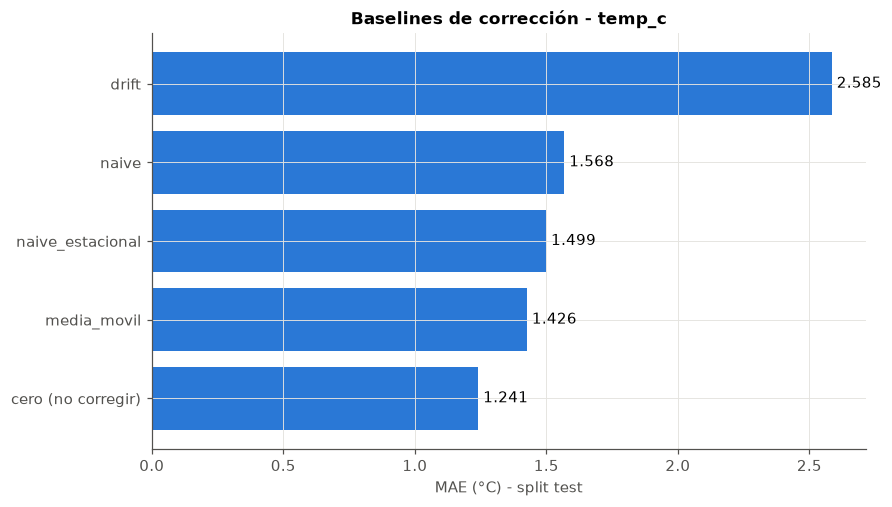

In [7]:
mae_test = tabla_metricas.xs('test', level='split')['MAE'].sort_values()

fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
ax.barh(mae_test.index, mae_test.values, color=AZUL)
ax.set(xlabel='MAE (°C) - split test', title=f'Baselines de corrección - {VARIABLE_OBJETIVO}')
for y, v in enumerate(mae_test.values):
    ax.text(v, y, f' {v:.3f}', va='center')
figuras['01_baselines_mae_test'] = fig
plt.show()

## 7. Guardado

In [8]:
import os

mejor = mae_test.index[0]
mejora_vs_cero = 100 * (1 - mae_test[mejor] / mae_test['cero (no corregir)'])
print(f'Mejor baseline para {VARIABLE_OBJETIVO}: "{mejor}" (MAE test = {mae_test[mejor]:.3f} °C, '
      f'{mejora_vs_cero:.1f}% mejor que no corregir)')

os.makedirs(OUT, exist_ok=True)
for nombre, fig in figuras.items():
    fig.savefig(OUT + f'{nombre}.png', dpi=300, bbox_inches='tight', facecolor='white')
tabla_metricas.to_csv(OUT + f'tabla_baselines_{VARIABLE_OBJETIVO}.csv')
print(f'Guardados {len(figuras)} gráfico(s) y 1 tabla en {OUT}')

Mejor baseline para temp_c: "cero (no corregir)" (MAE test = 1.241 °C, 0.0% mejor que no corregir)
Guardados 1 gráfico(s) y 1 tabla en ../data/out/modelado/
